<a href="https://colab.research.google.com/github/JuanCappelletti/12-RNN/blob/master/curva%20de%20bombas%20de%20rio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BOMBA SNZ 600-510/2
CURVA CARACTERÍSTICA H-Q

ECUACIÓN POLINÓMICA:
H(Q) = -7.6980540433e-10 Q³ +5.6221518828e-06 Q² -1.7862457546e-02 Q +62.98157

Coeficiente R² = 0.998618

PUNTOS ORIGINALES:
Caudal (m³/h) | AMT (mca)
------------------------------
           0 |     63.00
        2500 |     41.00
        3200 |     39.00
        3550 |     36.00
        4150 |     30.00
        4850 |     21.00


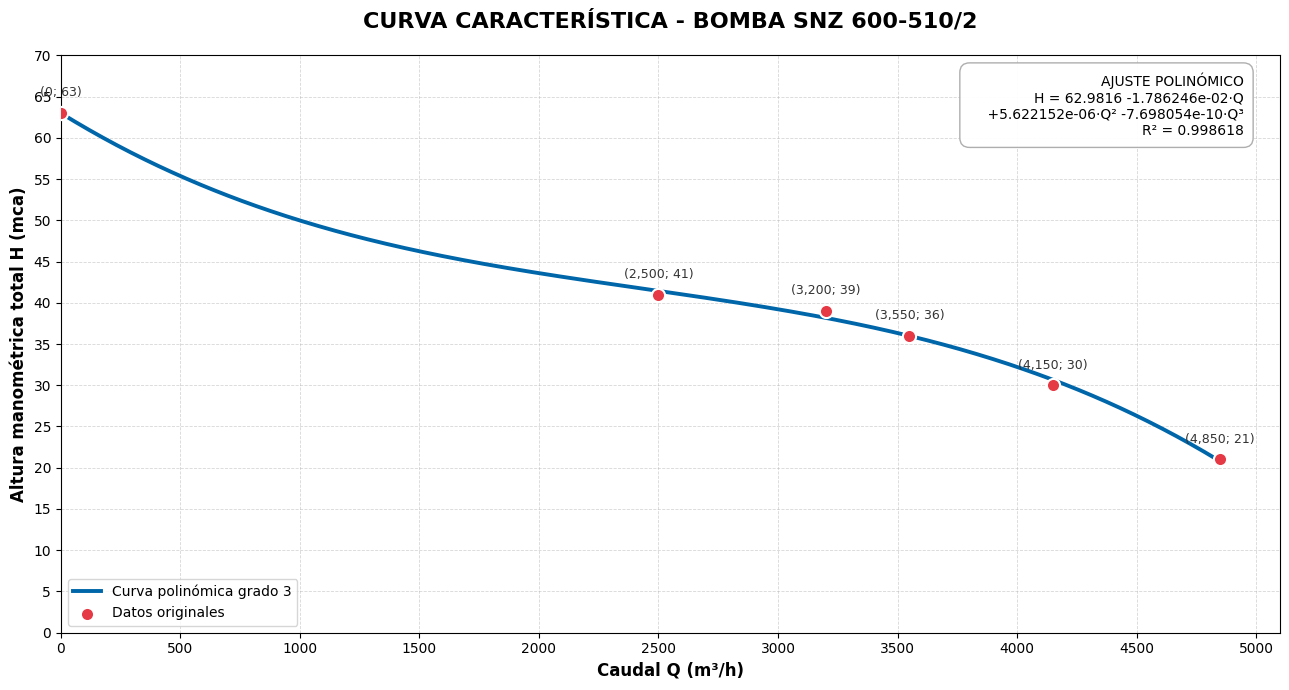

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# ============================================================
# CURVA CARACTERÍSTICA DE BOMBA SNZ 600-510/2
# Ajuste polinómico de tercer grado
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# ============================================================
# 1. DATOS DE LA BOMBA
# ============================================================

# Caudal en m³/h
Q = np.array([0, 2500, 3200, 3550, 4150, 4850])

# Altura manométrica total en mca
H = np.array([63, 41, 39, 36, 30, 21])

# ============================================================
# 2. AJUSTE POLINÓMICO
# ============================================================

grado = 3

coeficientes = np.polyfit(Q, H, grado)
polinomio = np.poly1d(coeficientes)

# Curva continua
Q_curva = np.linspace(0, 4850, 500)
H_curva = polinomio(Q_curva)

# Valores ajustados en puntos originales
H_ajustada = polinomio(Q)

# Coeficiente de determinación R²
ss_res = np.sum((H - H_ajustada)**2)
ss_tot = np.sum((H - np.mean(H))**2)

R2 = 1 - ss_res / ss_tot

# ============================================================
# 3. ECUACIÓN POLINÓMICA
# ============================================================

a, b, c, d = coeficientes

ecuacion = (
    f"H(Q) = {a:.10e} Q³ "
    f"{b:+.10e} Q² "
    f"{c:+.10e} Q "
    f"{d:+.5f}"
)

print("=" * 70)
print("BOMBA SNZ 600-510/2")
print("CURVA CARACTERÍSTICA H-Q")
print("=" * 70)

print("\nECUACIÓN POLINÓMICA:")
print(ecuacion)

print(f"\nCoeficiente R² = {R2:.6f}")

print("\nPUNTOS ORIGINALES:")
print("Caudal (m³/h) | AMT (mca)")
print("-" * 30)

for q, h in zip(Q, H):
    print(f"{q:12.0f} | {h:9.2f}")

# ============================================================
# 4. GRÁFICO PROFESIONAL
# ============================================================

fig, ax = plt.subplots(figsize=(13, 7))

# Curva polinómica
ax.plot(
    Q_curva,
    H_curva,
    color="#0066AA",
    linewidth=2.8,
    label="Curva polinómica grado 3"
)

# Puntos suministrados
ax.scatter(
    Q,
    H,
    color="#E63946",
    s=90,
    edgecolor="white",
    linewidth=1.5,
    zorder=5,
    label="Datos originales"
)

# Etiquetas de los puntos
for q, h in zip(Q, H):
    ax.annotate(
        f"({q:,.0f}; {h:.0f})",
        (q, h),
        xytext=(0, 12),
        textcoords="offset points",
        fontsize=9,
        ha="center",
        color="#333333"
    )

# Títulos
ax.set_title(
    "CURVA CARACTERÍSTICA - BOMBA SNZ 600-510/2",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Caudal Q (m³/h)",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Altura manométrica total H (mca)",
    fontsize=12,
    fontweight="bold"
)

# Escalas
ax.set_xlim(0, 5100)
ax.set_ylim(0, 70)

ax.set_xticks(np.arange(0, 5101, 500))
ax.set_yticks(np.arange(0, 71, 5))

# Cuadrícula
ax.grid(
    True,
    which="major",
    linestyle="--",
    linewidth=0.6,
    alpha=0.5
)

# Ecuación dentro del gráfico
texto_ecuacion = (
    "AJUSTE POLINÓMICO\n"
    f"H = {d:.4f} {c:+.6e}·Q\n"
    f"    {b:+.6e}·Q² {a:+.6e}·Q³\n"
    f"R² = {R2:.6f}"
)

ax.text(
    0.97,
    0.97,
    texto_ecuacion,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(
        boxstyle="round,pad=0.7",
        facecolor="white",
        edgecolor="#AAAAAA",
        alpha=0.95
    )
)

ax.legend(loc="lower left", fontsize=10)

plt.tight_layout()

# ============================================================
# 5. GUARDAR GRÁFICO
# ============================================================

nombre_archivo = "Curva_Bomba_SNZ_600-510-2.png"

plt.savefig(
    nombre_archivo,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ============================================================
# 6. DESCARGAR PNG
# ============================================================

files.download(nombre_archivo)
